In [1]:
import sys
import numpy as np
import pandas as pd
import sklearn

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)


Python: 3.12.10
NumPy: 2.5.5
Pandas: 3.1.1
Scikit-learn: 1.9.1


In [2]:
import os

NOTEBOOK_DIR = os.path.abspath('.')
SRC_DIR = os.path.abspath(os.path.join(NOTEBOOK_DIR, '..', 'src'))
SPLIT_DIR = os.path.abspath(os.path.join(NOTEBOOK_DIR, '..', 'data'))
MODEL_DIR = os.path.abspath(os.path.join(NOTEBOOK_DIR, '..', 'models'))
os.makedirs(MODEL_DIR, exist_ok=True)
sys.path.insert(0, SRC_DIR)

from logistic_regression import LogisticRegressionOVR
from neural_network import NeuralNetwork

print("Split files:", sorted(os.listdir(SPLIT_DIR)))

Split files: ['feature_names.csv', 'kaggle_test_preprocessed.csv', 'test_preprocessed.csv', 'train_preprocessed.csv', 'validation_preprocessed.csv']


In [3]:
import pandas as pd

train_df = pd.read_csv(os.path.join(SPLIT_DIR, "train_preprocessed.csv"))
val_df = pd.read_csv(os.path.join(SPLIT_DIR, "validation_preprocessed.csv"))
test_df = pd.read_csv(os.path.join(SPLIT_DIR, "test_preprocessed.csv"))

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

display(train_df.head())


Training: (1857, 213)
Validation: (619, 213)
Testing: (620, 213)


,Student_ID,categorical__Marital status_1,categorical__Marital status_2,categorical__Marital status_3,categorical__Marital status_4,categorical__Marital status_5,categorical__Marital status_6,categorical__Application mode_1,categorical__Application mode_2,categorical__Application mode_5,...,numerical__Curricular units 2nd sem (credited),numerical__Curricular units 2nd sem (enrolled),numerical__Curricular units 2nd sem (evaluations),numerical__Curricular units 2nd sem (approved),numerical__Curricular units 2nd sem (grade),numerical__Curricular units 2nd sem (without evaluations),numerical__Unemployment rate,numerical__Inflation rate,numerical__GDP,Target
0,2559,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.272014,-0.544408,0.270070,-0.806166,0.072612,-0.189562,0.884107,-1.095978,0.342088,Enrolled
1,2161,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,-0.272014,0.821146,0.014973,0.860556,0.823298,-0.189562,-0.287518,0.137979,0.757643,Graduate
2,1949,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,-0.272014,-0.089223,-0.495220,0.527212,0.586027,-0.189562,-0.816639,-1.458906,-1.368250,Graduate
3,135,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.800448,0.365962,0.014973,0.860556,0.274311,-0.189562,-1.496937,1.009008,0.136497,Graduate
4,4064,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.272014,-0.544408,0.270070,0.193868,0.473718,1.143832,1.753377,-0.660464,-0.405912,Graduate


The dataset was split into 60% training, 20% validation, and 20% testing, using 211 features and 3 target classes.

In [4]:
label_map = {
    "Dropout": 0,
    "Enrolled": 1,
    "Graduate": 2
}

feature_cols = [
    col for col in train_df.columns
    if col not in ["Student_ID", "Target"]
]

X_train = train_df[feature_cols].to_numpy(dtype=float)
X_val = val_df[feature_cols].to_numpy(dtype=float)
X_test = test_df[feature_cols].to_numpy(dtype=float)


y_train = train_df["Target"].map(label_map).to_numpy()
y_val = val_df["Target"].map(label_map).to_numpy()
y_test = test_df["Target"].map(label_map).to_numpy()

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("Classes:", np.unique(y_train))


X_train: (1857, 211)
X_val: (619, 211)
X_test: (620, 211)
y_train: (1857,)
Classes: [0 1 2]


Logistic Regression is implemented from scratch using One-vs-Rest classification and gradient descent to predict the three student outcomes.

##Logistic Regression from Scratch (One-vs-Rest)

The `LogisticRegressionOVR` class is in `src/logistic_regression.py` (imported above).

Train Logistic Regression

In [5]:
import time
from sklearn.metrics import accuracy_score, f1_score

lr_model = LogisticRegressionOVR(
    learning_rate=0.1,
    epochs=1000
)

start = time.perf_counter()
lr_model.fit(X_train, y_train)
lr_train_time = time.perf_counter() - start

lr_val_pred = lr_model.predict(X_val)

print("Training time:", round(lr_train_time, 2), "seconds")
print("Validation Accuracy:",
      round(accuracy_score(y_val, lr_val_pred), 4))
print("Validation F1:",
      round(f1_score(y_val, lr_val_pred, average="macro"), 4))


Training time: 1.08 seconds
Validation Accuracy: 0.7609
Validation F1: 0.683


Plot Logistic Regression Loss

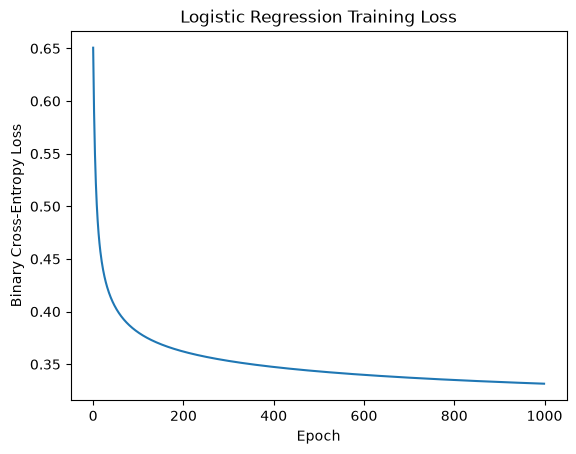

In [6]:
import matplotlib.pyplot as plt

plt.plot(lr_model.loss_history)
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Logistic Regression Training Loss")
plt.show()


### Artificial Neural Network (ANN)

The ANN is implemented from scratch using NumPy, with hidden layers, activation functions, softmax output, backpropagation, and mini-batch gradient descent.

The `NeuralNetwork` class is in `src/neural_network.py` (imported above).

Train ANN

In [7]:

ann_model = NeuralNetwork(
    hidden_layers=(32,),
    activation="relu",
    learning_rate=0.01,
    epochs=200,
    batch_size=32,
    random_state=42
)

start = time.perf_counter()
ann_model.fit(X_train, y_train)
ann_train_time = time.perf_counter() - start

ann_val_pred = ann_model.predict(X_val)

print("Training time:", round(ann_train_time, 2), "seconds")
print("Validation Accuracy:",
      round(accuracy_score(y_val, ann_val_pred), 4))
print("Validation F1:",
      round(f1_score(y_val, ann_val_pred, average="macro"), 4))


Training time: 1.72 seconds
Validation Accuracy: 0.7625
Validation F1: 0.698


Plot ANN Training Loss

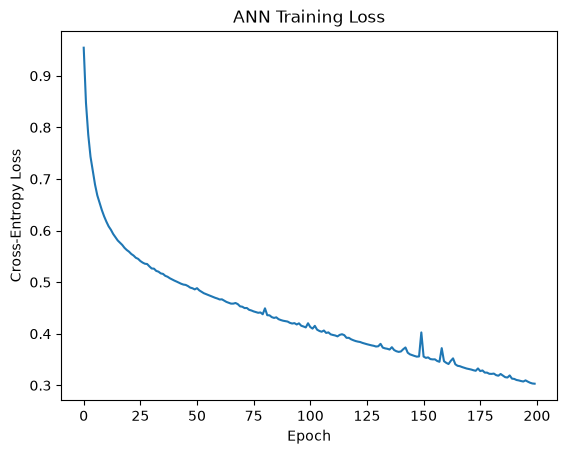

In [8]:
plt.plot(ann_model.loss_history)
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("ANN Training Loss")
plt.show()


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.neural_network import MLPClassifier

# Scikit-learn Logistic Regression (One-vs-Rest)
sk_lr = OneVsRestClassifier(
    LogisticRegression(max_iter=1000, random_state=42)
)

start = time.time()
sk_lr.fit(X_train, y_train)
sk_lr_time = time.time() - start

# Scikit-learn ANN
sk_ann = MLPClassifier(
    hidden_layer_sizes=(32,),
    activation="relu",
    solver="sgd",
    learning_rate_init=0.01,
    batch_size=32,
    max_iter=200,
    random_state=42
)

start = time.time()
sk_ann.fit(X_train, y_train)
sk_ann_time = time.time() - start


D:\Projects\chats\S2-ITB\13-IF5150-Advanced-Artificial-Intelligence\Assignments\Project-2\IF5150-Project-2\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Compare Validation Results

In [10]:
from sklearn.metrics import precision_score, recall_score
import pandas as pd

models = {
    "Logistic Regression (Scratch)": lr_model,
    "Logistic Regression (sklearn)": sk_lr,
    "ANN (Scratch)": ann_model,
    "ANN (sklearn)": sk_ann
}

train_times = {
    "Logistic Regression (Scratch)": lr_train_time,
    "Logistic Regression (sklearn)": sk_lr_time,
    "ANN (Scratch)": ann_train_time,
    "ANN (sklearn)": sk_ann_time
}

results = []

for name, model in models.items():
    start = time.time()
    pred = model.predict(X_val)
    inference_time = time.time() - start

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Macro Precision": precision_score(
            y_val, pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_val, pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_val, pred, average="macro", zero_division=0
        ),
        "Train Time (s)": train_times[name],
        "Inference Time (s)": inference_time
    })

val_results = pd.DataFrame(results)
display(val_results.round(4))


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Train Time (s),Inference Time (s)
0,Logistic Regression (Scratch),0.7609,0.7192,0.6697,0.6830,1.0813,0.0000
1,Logistic Regression (sklearn),0.7722,0.7321,0.6854,0.6990,0.1213,0.0010
2,ANN (Scratch),0.7625,0.7115,0.6898,0.6980,1.7187,0.0005
3,ANN (sklearn),0.7108,0.6527,0.6434,0.6471,3.7907,0.0011


In [11]:

lr_settings = [
    (0.05, 1000),
    (0.1, 1500),
    (0.2, 1500)
]

best_lr_score = -1
lr_tuning_results = []

for rate, epochs in lr_settings:
    model = LogisticRegressionOVR(
        learning_rate=rate,
        epochs=epochs
    )

    start = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - start

    pred = model.predict(X_val)
    accuracy = accuracy_score(y_val, pred)
    macro_f1 = f1_score(y_val, pred, average="macro")

    lr_tuning_results.append({
        "Learning Rate": rate,
        "Epochs": epochs,
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    })

    if accuracy > best_lr_score:
        best_lr_score = accuracy
        lr_model = model
        lr_train_time = train_time

display(pd.DataFrame(lr_tuning_results).round(4))
print("Best Logistic Regression Accuracy:", round(best_lr_score, 4))


,Learning Rate,Epochs,Accuracy,Macro F1
0,0.05,1000,0.7577,0.6751
1,0.10,1500,0.7625,0.6866
2,0.20,1500,0.7674,0.6905


Best Logistic Regression Accuracy: 0.7674


In [12]:

ann_settings = [
    (32, 0.01, 300),
    (64, 0.01, 300),
    (32, 0.03, 300)
]

best_ann_score = -1
ann_tuning_results = []

for neurons, rate, epochs in ann_settings:
    model = NeuralNetwork(
        hidden_layers=(neurons,),
        activation="relu",
        learning_rate=rate,
        epochs=epochs,
        batch_size=32,
        random_state=42
    )

    start = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - start

    pred = model.predict(X_val)
    accuracy = accuracy_score(y_val, pred)
    macro_f1 = f1_score(y_val, pred, average="macro")

    ann_tuning_results.append({
        "Neurons": neurons,
        "Learning Rate": rate,
        "Epochs": epochs,
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    })

    if accuracy > best_ann_score:
        best_ann_score = accuracy
        ann_model = model
        ann_train_time = train_time

display(pd.DataFrame(ann_tuning_results).round(4))
print("Best ANN Accuracy:", round(best_ann_score, 4))


,Neurons,Learning Rate,Epochs,Accuracy,Macro F1
0,32,0.01,300,0.7415,0.6857
1,64,0.01,300,0.7399,0.6750
2,32,0.03,300,0.7060,0.6454


Best ANN Accuracy: 0.7415


In [13]:

from sklearn.metrics import classification_report, confusion_matrix

print("Logistic Regression Validation Results")

pred = lr_model.predict(X_val)

print(classification_report(
    y_val,
    pred,
    labels=[0, 1, 2],
    target_names=["Dropout", "Enrolled", "Graduate"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_val, pred, labels=[0, 1, 2]))


Logistic Regression Validation Results
              precision    recall  f1-score   support

     Dropout       0.83      0.72      0.77       199
    Enrolled       0.57      0.37      0.45       111
    Graduate       0.78      0.94      0.85       309

    accuracy                           0.77       619
   macro avg       0.73      0.68      0.69       619
weighted avg       0.76      0.77      0.75       619

Confusion Matrix:
[[144  22  33]
 [ 19  41  51]
 [ 10   9 290]]


In [14]:

# Restore original Logistic Regression settings
lr_model = LogisticRegressionOVR(
    learning_rate=0.1,
    epochs=1000
)

start = time.perf_counter()
lr_model.fit(X_train, y_train)
lr_train_time = time.perf_counter() - start

# Restore original ANN settings
ann_model = NeuralNetwork(
    hidden_layers=(32,),
    activation="relu",
    learning_rate=0.01,
    epochs=200,
    batch_size=32,
    random_state=42
)

start = time.perf_counter()
ann_model.fit(X_train, y_train)
ann_train_time = time.perf_counter() - start

print("Logistic Regression Accuracy:",
      round(accuracy_score(y_val, lr_model.predict(X_val)), 4))

print("ANN Accuracy:",
      round(accuracy_score(y_val, ann_model.predict(X_val)), 4))


Logistic Regression Accuracy: 0.7609
ANN Accuracy: 0.7625


In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

models = {
    "Logistic Regression (Scratch)": lr_model,
    "Logistic Regression (sklearn)": sk_lr,
    "ANN (Scratch)": ann_model,
    "ANN (sklearn)": sk_ann
}

test_results = []

for name, model in models.items():
    start = time.perf_counter()
    predictions = model.predict(X_test)
    inference_time = time.perf_counter() - start

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Inference Time (s)": inference_time
    })

    print("\n", name)
    print(classification_report(
        y_test, predictions,
        labels=[0, 1, 2],
        target_names=["Dropout", "Enrolled", "Graduate"],
        zero_division=0
    ))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions, labels=[0, 1, 2]))

test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(4))



 Logistic Regression (Scratch)
              precision    recall  f1-score   support

     Dropout       0.81      0.78      0.79       199
    Enrolled       0.55      0.30      0.39       111
    Graduate       0.78      0.93      0.85       310

    accuracy                           0.77       620
   macro avg       0.71      0.67      0.68       620
weighted avg       0.75      0.77      0.75       620

Confusion Matrix:
[[155  16  28]
 [ 24  33  54]
 [ 12  11 287]]

 Logistic Regression (sklearn)
              precision    recall  f1-score   support

     Dropout       0.83      0.78      0.81       199
    Enrolled       0.61      0.40      0.48       111
    Graduate       0.80      0.93      0.86       310

    accuracy                           0.79       620
   macro avg       0.75      0.70      0.71       620
weighted avg       0.77      0.79      0.77       620

Confusion Matrix:
[[155  16  28]
 [ 21  44  46]
 [ 10  12 288]]

 ANN (Scratch)
              precision    rec

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Inference Time (s)
0,Logistic Regression (Scratch),0.7661,0.7131,0.6673,0.6754,0.0003
1,Logistic Regression (sklearn),0.7855,0.7467,0.7014,0.7144,0.0009
2,ANN (Scratch),0.7661,0.7128,0.6943,0.7014,0.0006
3,ANN (sklearn),0.7516,0.6960,0.6852,0.6887,0.0011


On the test set, Logistic Regression and ANN from scratch both achieved 76.61% accuracy. The ANN obtained a higher Macro F1-score (0.7014), while scikit-learn Logistic Regression achieved the highest accuracy (78.55%).

In [16]:
import os
import numpy as np

lr_model.save(os.path.join(MODEL_DIR, "logistic_regression.pkl"))
ann_model.save(os.path.join(MODEL_DIR, "ann.pkl"))

loaded_lr = LogisticRegressionOVR.load(
    os.path.join(MODEL_DIR, "logistic_regression.pkl")
)

loaded_ann = NeuralNetwork.load(
    os.path.join(MODEL_DIR, "ann.pkl")
)

lr_match = np.array_equal(
    lr_model.predict(X_test),
    loaded_lr.predict(X_test)
)

ann_match = np.array_equal(
    ann_model.predict(X_test),
    loaded_ann.predict(X_test)
)

print("Logistic Regression predictions match:", lr_match)
print("ANN predictions match:", ann_match)


Logistic Regression predictions match: True
ANN predictions match: True
